# Ejercicio 4 · ¿Cuánto vale esta casa?


**Módulo 5072 · SAA · UD3 · Métodos ensemble** · 

Una inmobiliaria de Seattle quiere estimar el precio de venta de una casa a partir de sus características: metros, habitaciones, baños, año, zona...

- **Qué predecimos:** el precio en dólares (`price`). Es **regresión**.
- **Métrica:** el **MAE**, cuántos dólares se equivoca el modelo de media.

**Qué vas a hacer:** entrenar cuatro modelos, compararlos en una tabla y elegir uno.

**Lo nuevo:** aquí hay muchas casas, así que no usamos validación cruzada. Separamos a mano tres trozos: **train, validación y test**.

**Cómo trabajar:**
- Las celdas que dicen **«ya está hecha»**: solo ejecútalas y lee el resultado.
- Las celdas **«# Tu código»**: escribe tú el código. Si te atascas, abre la **Pista 1** (qué hay que hacer) y, si hace falta, la **Pista 2** (el código con huecos `___`).
- Al final miras **en qué variables se fija** el modelo.

## 1 · Preparación

Estas celdas ya están hechas: ejecútalas una a una y mira qué sale.

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor

DATA = "../data/"

SEMILLA = 42

# 1. Cargar los datos. Algunas casas se vendieron dos veces: nos quedamos con la última venta
df = pd.read_csv(DATA + "kc_house_data.csv")
df = df.drop_duplicates("id", keep="last")
print(df.shape)

(21436, 21)


In [23]:
# 2. X (las pistas) e y (el precio). Quitamos id (un código) y date (la fecha como texto)
X = df.drop(columns=["id", "date", "price"])
y = df["price"]

In [24]:
# 3. Tres trozos: train (60 %), validación (20 %) y test (20 %)
# Primero apartamos el 20 % para el test
X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
# Del resto (80 %), separamos una cuarta parte para validación: 0,25 × 80 % = 20 % del total
X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=SEMILLA)

print("Train:", len(X_train), "casas · Validación:", len(X_val), "· Test:", len(X_test))

Train: 12861 casas · Validación: 4287 · Test: 4288


In [25]:
# 4. No hay huecos ni columnas de texto: no hay nada que rellenar ni convertir

In [26]:
# 5. Sin validación cruzada: con más de 4.000 casas, un solo trozo de validación ya es fiable

In [27]:
# 6. evaluar(): entrena el modelo UNA vez, solo con train,
#    y mide el error en validación (casas que no ha visto) y en train. El test no se toca.
def evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    return {"modelo": nombre,
            "MAE val": mean_absolute_error(y_val, modelo.predict(X_val)),
            "R2 val": r2_score(y_val, modelo.predict(X_val)),
            "MAE train": mean_absolute_error(y_train, modelo.predict(X_train))}

def mostrar(resultados):
    return pd.DataFrame(resultados).round({"MAE val": 0, "R2 val": 3, "MAE train": 0})

In [28]:
# 7. Baseline: el modelo más tonto, que dice siempre el precio medio del train
resultados = [{"modelo": "Baseline (la media)",
               "MAE val": mean_absolute_error(y_val, np.full(len(y_val), y_train.mean())),
               "R2 val": 0.0,
               "MAE train": mean_absolute_error(y_train, np.full(len(y_train), y_train.mean()))}]
print("Listo")

Listo


**Qué han hecho estas celdas**
1. Carga las casas y quita las ventas repetidas de la misma casa.
2. Separa `X` (las pistas) e `y` (el precio).
3. Separa tres trozos: **train** (60 %), **validación** (20 %) y **test** (20 %).
4. Aquí no hay huecos ni texto.
5. Aquí no hay validación cruzada.
6. Crea `evaluar()`: entrena con train y mide en validación. Y `mostrar()`.
7. Crea la tabla `resultados` con el **baseline**.

> **Para entenderlo · Train, validación y test**
>
> | Trozo | Casas | Para qué |
> |---|---|---|
> | Train (60 %) | 12.861 | El modelo aprende con ellas |
> | Validación (20 %) | 4.287 | Comparamos los modelos y elegimos uno |
> | Test (20 %) | 4.288 | Solo al final, una vez, para comprobar el elegido |
>
> En los otros ejercicios, la validación eran los 5 trozos de la validación cruzada. Aquí es un trozo fijo.
>
> - **Ventaja:** cada modelo se entrena una vez y no cinco. Va 5 veces más rápido.
> - **Inconveniente:** no tenemos `±`. No sabemos cuánto cambiaría el resultado con otro trozo de validación.
>
> Con 21.000 casas vale, porque la validación tiene más de 4.000. Con los 614 préstamos del ejercicio 5, una validación fija tendría unas 120 solicitudes: el resultado dependería mucho de cuáles cayeran ahí.

**Cómo leer la tabla** (dos métricas)
- `MAE val`: cuántos dólares se equivoca de media con casas que no ha visto (el trozo de validación). **Es la que usamos para comparar**: cuanto menos, mejor.
- `R2 val`: qué parte de las diferencias de precio entre casas explica el modelo (0 = como decir siempre la media, 1 = perfecto).
- `MAE train`: el error con las casas que ya ha visto. Si es mucho más bajo que `MAE val`, el modelo **memoriza**.

In [29]:
mostrar(resultados)

,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.0,235368.0


**Fíjate:** ¿Cuántos dólares se equivoca de media el baseline? Cualquier modelo útil tiene que equivocarse bastante menos.

*Tu respuesta:*

Se equivoca de media en 237087, a partir de aqui lo que desarrollemos tiene que equivocarse menos

## 2 · Tu turno: entrena y compara

**Tarea 1 · Un árbol sin límite.** Evalúalo y añádelo a `resultados`.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Llama a `evaluar()` con un nombre y el modelo `DecisionTreeRegressor` sin límite (sin `max_depth`). Añade la fila a `resultados` con `append` y muestra la tabla.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Árbol sin límite", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [30]:
# Tu código
resultados.append(evaluar("Árbol sin límite", DecisionTreeRegressor(random_state=SEMILLA)))
mostrar(resultados)

,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.000,235368.0
1,Árbol sin límite,103474.0,0.695,0.0


**Fíjate:** Compara `MAE train` y `MAE val`. ¿Memoriza?

*Tu respuesta:*

MAE train 0.0 vs MAE val 103474.0. Aún asíu mejora el baseline 237087 vs 103474

**Tarea 2 · Random Forest de 300 árboles.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `RandomForestRegressor` y el número de árboles va en `n_estimators`. `n_jobs=-1` usa todos los núcleos del ordenador: va más rápido.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Random Forest", ___(n_estimators=___, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)
```

</details>

In [31]:
# Tu código
resultados.append(evaluar("Random Forest", RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)

,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.000,235368.0
1,Árbol sin límite,103474.0,0.695,0.0
2,Random Forest,70337.0,0.870,25881.0


**Fíjate:** ¿Mejora al árbol? ¿Cuántos dólares?

*Tu respuesta:*

Si lo mejora. Baja 33.137 dólares de error medio.

**Tarea 3 · XGBoost por defecto.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `XGBRegressor`. Sin tocar nada: 100 árboles de hasta 6 preguntas y `learning_rate` 0,3.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("XGBoost por defecto", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [32]:
# Tu código
resultados.append(evaluar("XGBoost por defecto", XGBRegressor(random_state=SEMILLA)))
mostrar(resultados)

,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.000,235368.0
1,Árbol sin límite,103474.0,0.695,0.0
2,Random Forest,70337.0,0.870,25881.0
3,XGBoost por defecto,69973.0,0.876,36780.0


**Fíjate:** Compara `MAE train` y `MAE val`. ¿Memoriza?

*Tu respuesta:*

Sí, un poco.

Train 36780 y val 69973, hueco de 33k.

**Tarea 4 · XGBoost con frenos.** Pon:
- `max_depth=3`: árboles pequeños.
- `learning_rate=0.05`: poco caso a cada árbol.
- `n_estimators=300`: como le hacemos poco caso a cada uno, hacen falta más árboles.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Guarda el modelo en la variable `xgb_frenos` (la usaremos en el test) y después pásalo a `evaluar()`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
xgb_frenos = XGBRegressor(max_depth=___, learning_rate=___, n_estimators=___, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)
```

</details>

In [33]:
# Tu código
xgb_frenos =  XGBRegressor(max_depth=3, learning_rate=0.05, n_estimators=300, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)

,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.000,235368.0
1,Árbol sin límite,103474.0,0.695,0.0
2,Random Forest,70337.0,0.870,25881.0
3,XGBoost por defecto,69973.0,0.876,36780.0
4,XGBoost con frenos,75245.0,0.867,68783.0


**Fíjate:** Compáralo con el XGBoost por defecto. ¿Memoriza menos? ¿Mejora `MAE val`?

*Tu respuesta:*

Memoriza menos, el hueco pasa de 33k a 6k, pero MAE val empeora de 69973 a 75245.

> **Para entenderlo · `GridSearchCV` con train, validación y test**
>
> En la tarea 4 vimos que los frenos de XGBoost eran demasiados. ¿Cuáles son los buenos? `GridSearchCV` prueba **todas las combinaciones** de hiperparámetros que le demos y se queda con la mejor.
>
> - Para elegir, hace por dentro su **propia validación cruzada** (`cv=3`) **solo con el train**.
> - Después, nosotros comprobamos el ganador con `evaluar()` en **nuestra validación**, como al resto de modelos.
> - El test sigue sin tocarse.
>
> Ojo: tarda. Cuantas más combinaciones, más modelos entrena.

**Tarea 5 · Random Forest ajustado con `GridSearchCV`.** Prueba `max_features` 0,3, 0,5 y 1,0, y `min_samples_leaf` 1 y 5 (6 combinaciones). Usamos 100 árboles para que no tarde tanto. Tarda 1 o 2 minutos.

<details><summary><b>Pista 1</b> · qué hay que hacer<b></b></summary>

Es como el `gs_rf` del gimnasio. `scoring="neg_mean_absolute_error"`: scikit-learn siempre busca el número más alto, así que le damos el error en negativo. El mejor modelo, ya entrenado, queda en `gs_rf.best_estimator_`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
from sklearn.model_selection import GridSearchCV

rejilla = {"max_features": [0.3, 0.5, 1.0], "min_samples_leaf": [1, 5]}
gs_rf = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
                     rejilla, cv=3, scoring="neg_mean_absolute_error")
gs_rf.fit(X_train, y_train)          # solo con el train
print("Mejor combinación:", gs_rf.best_params_)

resultados.append(evaluar("Random Forest ajustado", gs_rf.___))
mostrar(resultados)
```

</details>

In [34]:
from sklearn.model_selection import GridSearchCV

rejilla = {"max_features": [0.3, 0.5, 1.0], "min_samples_leaf": [1, 5]}
gs_rf = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
                     rejilla, cv=3, scoring="neg_mean_absolute_error")
gs_rf.fit(X_train, y_train)          # solo con el train
print("Mejor combinación:", gs_rf.best_params_)

resultados.append(evaluar("Random Forest ajustado", gs_rf.best_estimator_))
mostrar(resultados)

Mejor combinación: {'max_features': 0.5, 'min_samples_leaf': 1}


,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.0,0.000,235368.0
1,Árbol sin límite,103474.0,0.695,0.0
2,Random Forest,70337.0,0.870,25881.0
3,XGBoost por defecto,69973.0,0.876,36780.0
4,XGBoost con frenos,75245.0,0.867,68783.0
5,Random Forest ajustado,70211.0,0.873,26124.0


**Fíjate:** ¿Qué combinación gana? ¿Mejora al Random Forest de la tarea 2 en `MAE val`?

*Tu respuesta:*

Gana max_features 0.5 y min_samples_leaf 1 y sí mejora, baja MAE val de 70337 a 70211.

**Tarea 6 · XGBoost ajustado con `GridSearchCV`.** Prueba `n_estimators` 300 y 800, `learning_rate` 0,05 y 0,1, y `max_depth` 3 y 6 (8 combinaciones). Tarda 1 o 2 minutos.

<details><summary><b>Pista 1</b> · qué hay que hacer<b></b></summary>

Igual que la tarea 5, con `XGBRegressor` y otra rejilla. Guárdalo en `gs_xgb`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
rejilla = {"n_estimators": [___], "learning_rate": [___], "max_depth": [___]}
gs_xgb = GridSearchCV(___(random_state=SEMILLA), rejilla, cv=3, scoring="neg_mean_absolute_error")
gs_xgb.fit(X_train, y_train)
print("Mejor combinación:", gs_xgb.best_params_)

resultados.append(evaluar("XGBoost ajustado", ___))
mostrar(resultados)
```

</details>

In [35]:
# Tu código
gs_xgb = GridSearchCV(XGBRegressor(random_state=SEMILLA),
                      {"n_estimators": [300, 800], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
                      cv=3, scoring="neg_mean_absolute_error")

gs_xgb.fit(X_train, y_train)
print("Mejores hiperparámetros:", gs_xgb.best_params_)
resultados.append(evaluar("XGBoost ajustado", gs_xgb.best_estimator_))
pd.DataFrame(resultados).round(3)

Mejores hiperparámetros: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 800}


,modelo,MAE val,R2 val,MAE train
0,Baseline (la media),237087.204,0.000,235368.267
1,Árbol sin límite,103474.202,0.695,0.268
2,Random Forest,70336.590,0.870,25880.978
3,XGBoost por defecto,69972.867,0.876,36780.338
4,XGBoost con frenos,75244.976,0.867,68782.819
5,Random Forest ajustado,70210.571,0.873,26123.735
6,XGBoost ajustado,65256.186,0.880,30850.759


**Fíjate:** ¿Qué combinación gana? ¿Mejora a XGBoost por defecto (tarea 3) y al de frenos (tarea 4)?

*Tu respuesta:*

Gana learning_rate 0.05, max_depth 6 y n_estimators 800 y sí mejora a los dos, baja MAE val de 69972 por defecto y 75244 con frenos a 65256.

## 3 · ¿Cuál elegimos?

Esta celda ya está hecha: ejecútala. Ordena la tabla: el mejor queda arriba.

In [36]:
mostrar(pd.DataFrame(resultados).sort_values("MAE val", ascending=True))

,modelo,MAE val,R2 val,MAE train
6,XGBoost ajustado,65256.0,0.880,30851.0
3,XGBoost por defecto,69973.0,0.876,36780.0
5,Random Forest ajustado,70211.0,0.873,26124.0
2,Random Forest,70337.0,0.870,25881.0
4,XGBoost con frenos,75245.0,0.867,68783.0
1,Árbol sin límite,103474.0,0.695,0.0
0,Baseline (la media),237087.0,0.000,235368.0


Contesta:
1. ¿Qué modelo gana?
2. Resta su `MAE val` y el del segundo. Aquí no hay `±`: ¿es mucha diferencia comparada con lo que se equivocan (unos 70.000 dólares)?
3. ¿Cuál eliges? Si casi empatan, elige el más sencillo o el más rápido.

*Tu respuesta:*

1. Gana XGBoost ajustado con 65256.
2. 69973 - 65256 = 4717, no es mucha para 70k que se equivocan, es como un 6%.
3. Elijo XGBoost por defecto, casi empata y es más sencillo y rápido que el ajustado de 800 árboles.

## 4 · ¿En qué se fija el modelo?

> **Para entenderlo · Importancia de las variables**
>
> Un Random Forest entrenado guarda en `feature_importances_` cuánto le ha servido cada variable para hacer sus preguntas. Cada número va de 0 a 1 y entre todas suman 1.
>
> - Una variable con importancia alta separa bien los casos.
> - **No dice hacia dónde**: no sabemos si subirla aumenta o baja la predicción.
> - **No dice que sea la causa**: solo que al modelo le sirve para acertar.

**4.1** Entrena un Random Forest de 300 árboles con todo el train y dibuja la importancia de cada variable. El gráfico ya está hecho: solo rellena los huecos.

<details><summary><b>Pista</b></summary>

Para entrenar: `.fit(X_train, y_train)`. La importancia está en `rf.feature_importances_`.

</details>

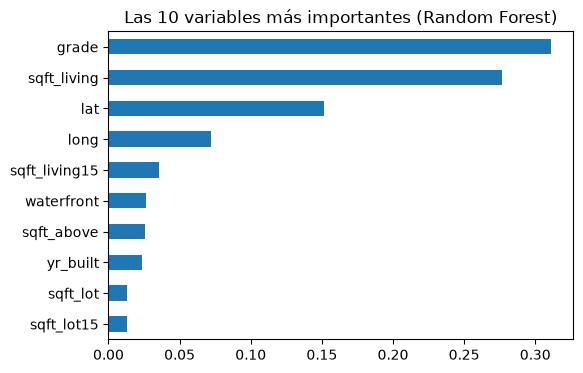

In [37]:
rf = RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)
importancia = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

importancia.tail(10).plot.barh(figsize=(6, 4), title="Las 10 variables más importantes (Random Forest)")
plt.show()

**Cómo leer el gráfico:** cada barra es una variable. Cuanto más larga, más le sirve al modelo. La más importante queda arriba.

Contesta:
1. ¿Cuál es la variable más importante? ¿Tiene sentido?
2. ¿Cuáles son la segunda y la tercera?
3. ¿Dónde quedan la latitud (`lat`) y la longitud (`long`)? ¿Qué crees que significa?

*Tu respuesta:*

1. La más importante es grade, sí tiene sentido es la calidad de la casa.
2. Segunda sqft_living y tercera lat.
3. Lat queda 3ª y long 4ª, significa que la ubicación importa mucho para el precio.

## 5 · El test, una sola vez

Esta celda ya está hecha: ejecútala. Juntamos train y validación para que los dos modelos ajustados aprendan con más casas. Después los probamos en el test, que hasta ahora no habíamos tocado.

In [38]:
# El modelo final aprende con train + validación juntos (más casas)
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

rf_final = gs_rf.best_estimator_.fit(X_train_val, y_train_val)
xgb_final = gs_xgb.best_estimator_.fit(X_train_val, y_train_val)

print("Random Forest ajustado · MAE test:", round(mean_absolute_error(y_test, rf_final.predict(X_test))))
print("XGBoost ajustado       · MAE test:", round(mean_absolute_error(y_test, xgb_final.predict(X_test))))

Random Forest ajustado · MAE test: 65725
XGBoost ajustado       · MAE test: 60174


**Fíjate:** ¿El resultado del test se parece al de validación (`MAE val`)? Si se parece, la validación nos dijo la verdad.

*Tu respuesta:*

Sí se parece, la validación dijo la verdad.
RF ajustado val 70211 y test 65725, XGB ajustado val 65256 y test 60174, baja unos 5k pero sigue en el mismo rango, no se dispara.

## 6 · Conclusión

En dos o tres frases: ¿qué modelo eliges? ¿Por qué? Usa números de la tabla.

*Tu respuesta:*

Elijo XGBoost ajustado porque es el que menos se equivoca, tiene MAE val 65256 y MAE test 60174, 5500 menos que el RF ajustado que tiene 65725 en test.

## 7 · Experimenta: tres pruebas más

Tres pruebas cortas. Van en una tabla aparte, `extra`, para no mezclarlas con la de antes.

**Extra 1 · ¿Cuántos árboles hacen falta?** Esta celda ya está hecha: ejecútala. Entrena Random Forest con 10, 50 y 100 árboles.

In [39]:
extra = []
for n in [10, 50, 100]:
    extra.append(evaluar(f"Random Forest de {n} árboles", RandomForestRegressor(n_estimators=n, random_state=SEMILLA, n_jobs=-1)))
mostrar(extra)

,modelo,MAE val,R2 val,MAE train
0,Random Forest de 10 árboles,74709.0,0.851,30232.0
1,Random Forest de 50 árboles,71239.0,0.865,26662.0
2,Random Forest de 100 árboles,70685.0,0.868,26146.0


**Fíjate:** ¿Mejora al pasar de 10 a 50 árboles? ¿Y de 50 a 100? ¿Empeora alguna vez al poner más árboles?

*Tu respuesta:*

Sí mejora de 10 a 50 baja de 74709 a 71239 y de 50 a 100 baja a 70685, pero ya mejora poco. No empeora nunca al poner más árboles.

**Extra 2 · Un árbol con límite.** Un solo árbol, pero de 5 preguntas como máximo (`max_depth=5`). Cambia los `___`.

In [40]:
extra.append(evaluar("Árbol de 5 preguntas", DecisionTreeRegressor(max_depth=5, random_state=SEMILLA)))
mostrar(extra)

,modelo,MAE val,R2 val,MAE train
0,Random Forest de 10 árboles,74709.0,0.851,30232.0
1,Random Forest de 50 árboles,71239.0,0.865,26662.0
2,Random Forest de 100 árboles,70685.0,0.868,26146.0
3,Árbol de 5 preguntas,117567.0,0.659,112823.0


**Fíjate:** Compáralo con el árbol sin límite de la tabla de antes. ¿Memoriza menos? ¿Llega a los ensembles?

*Tu respuesta:*

Sí memoriza menos, antes era 0 de train y 103474 de val hueco enorme y ahora 112823 train vs 117567 val hueco de 5k. Pero no llega a los ensembles que están en 70k y este está en 117567.

**Extra 3 · Mucho caso a cada árbol.** El mismo XGBoost con frenos, pero con `learning_rate=0.5` en lugar de 0,05. Cambia el `___`.

In [41]:
xgb_rapido = XGBRegressor(max_depth=3, learning_rate=0.5, n_estimators=300, random_state=SEMILLA)
extra.append(evaluar("XGBoost con learning_rate 0,5", xgb_rapido))
mostrar(extra)

,modelo,MAE val,R2 val,MAE train
0,Random Forest de 10 árboles,74709.0,0.851,30232.0
1,Random Forest de 50 árboles,71239.0,0.865,26662.0
2,Random Forest de 100 árboles,70685.0,0.868,26146.0
3,Árbol de 5 preguntas,117567.0,0.659,112823.0
4,"XGBoost con learning_rate 0,5",71855.0,0.864,48743.0


**Fíjate:** Compáralo con el XGBoost con frenos (0,05). ¿Memoriza más? ¿Mejora o empeora `MAE val`?

*Tu respuesta:*

Memoriza más, train baja de 68783 a 48743 y el hueco sube de 6k a 23k. Mejora MAE val de 75244 a 71855.